# Fine-Tuning Model dengan Data Baru Diambil dari Kamar Kos

## 1. Prapemrosesan Dataset Lokal & Imputasi Sirkadian
Bagian ini memuat dataset spesifik (kamar kos), melakukan pembersihan, dan menyusun data beruntun (time-series) interval 15-menit. Jika terdapat celah data yang panjang, kita menggunakan median historis per jam (hour-of-day median) agar tren beban harian tetap terjaga.

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error

tf.keras.utils.set_random_seed(42)

# ==============================================================================
# 1. MEMUAT DATASET & FILTER BARIS (TEGANGAN 190-235V DAN DAYA > 0 W)
# ==============================================================================
FILE_NAME = "power_meter_20261024_052105.csv"  # Sesuaikan nama file
df_raw = pd.read_csv(FILE_NAME)

COL_V = "Tegangan (V)"
COL_W = "Daya Aktif (W)"
for col in (COL_V, COL_W):
    df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

df_raw["Timestamp"] = pd.to_datetime(df_raw["Timestamp"], errors="coerce")
df_raw = (
    df_raw.dropna(subset=["Timestamp"])
    .drop_duplicates(subset="Timestamp", keep="last")
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

total_awal = len(df_raw)
print(f"Total baris mentah terbaca: {total_awal:,}")

# Batas fisik tegangan operasional kamar kos
MIN_VOLT = 190.0
MAX_VOLT = 235.0

mask_volt_ok = df_raw[COL_V].between(MIN_VOLT, MAX_VOLT)
mask_power_ok = df_raw[COL_W].notna() & (df_raw[COL_W] > 0)
valid_row_mask = mask_volt_ok & mask_power_ok

baris_dibuang = (~valid_row_mask).sum()
df_clean = df_raw[valid_row_mask].copy()

print(f"Total baris outlier dibersihkan: {baris_dibuang:,} baris ({baris_dibuang/total_awal*100:.2f}%)")
print(f"Sisa baris data bersih & valid: {len(df_clean):,} baris")

# ==============================================================================
# 2. RESAMPLING 15 MENIT & REKONSTRUKSI KONTINU (PROFIL SIRKADIAN)
# ==============================================================================
print("\nMelakukan agregasi grid waktu 15-menit dan imputasi sirkadian")
df_clean_indexed = df_clean.set_index("Timestamp")

df_15m_power = df_clean_indexed[COL_W].resample("15min").mean()
df_15m_volt = df_clean_indexed[COL_V].resample("15min").mean()

room_power_baseline = df_15m_power.median() if not np.isnan(df_15m_power.median()) else 25.0
room_volt_baseline = df_15m_volt.median() if not np.isnan(df_15m_volt.median()) else 216.0

# Rekonstruksi Celah: Interpolasi singkat + Imputasi berbasis jam sirkadian (0-23)
df_filled_power = df_15m_power.interpolate(method="time", limit=4)
hourly_power_median = df_filled_power.groupby(df_filled_power.index.hour).transform("median")
df_filled_power = df_filled_power.fillna(hourly_power_median).fillna(room_power_baseline).bfill().ffill()

df_energy = (df_filled_power / 1000.0 * 0.25).to_frame(name="energy_kwh")
series_energy = df_energy["energy_kwh"]
total_blocks = len(series_energy)
print(f"Total interval 15-menit kontinu: {total_blocks} blok ({total_blocks/4:.1f} jam)")

Total baris mentah terbaca: 115,279
Total baris outlier dibersihkan: 4,151 baris (3.60%)
Sisa baris data bersih & valid: 111,128 baris

Melakukan agregasi grid waktu 15-menit dan imputasi sirkadian
Total interval 15-menit kontinu: 562 blok (140.5 jam)


## 2. Rekayasa Fitur dan Pembagian Train-Test
Mengekstrak 8 fitur (historis & sirkadian) dan 4 target horizon ke depan. Data dipisah menjadi set latih dan uji menggunakan batasan kronologis murni dengan purge gap untuk menghindari kebocoran data.

In [16]:
# ==============================================================================
# 3. REKAYASA 8 FITUR MASUKAN (X) & 4 TARGET MASA DEPAN (Y)
# ==============================================================================
print("\nMengekstrak 8 fitur masukan dan 4 target multi-horizon")
X_list, Y_list = [], []

for i in range(96, total_blocks - 96):
    x0 = series_energy.iloc[i]
    x1 = series_energy.iloc[i - 1]
    x2 = series_energy.iloc[i - 2]
    x3 = series_energy.iloc[i - 3]
    x4 = series_energy.iloc[i - 24 : i].mean() 
    x5 = series_energy.iloc[i - 96]
    
    hour_dec = series_energy.index[i].hour + (series_energy.index[i].minute / 60.0)
    x6 = np.sin(2.0 * np.pi * hour_dec / 24.0)
    x7 = np.cos(2.0 * np.pi * hour_dec / 24.0)

    q1 = series_energy.iloc[i : i + 24].sum()
    q2 = series_energy.iloc[i + 24 : i + 48].sum()
    q3 = series_energy.iloc[i + 48 : i + 72].sum()
    q4 = series_energy.iloc[i + 72 : i + 96].sum()

    X_list.append([x0, x1, x2, x3, x4, x5, x6, x7])
    Y_list.append([q1, q2, q3, q4])

X = np.array(X_list, dtype=np.float32)
Y = np.array(Y_list, dtype=np.float32)
print(f"Total sampel terkumpul: {len(X)}")

# ==============================================================================
# 4. PEMBAGIAN DATA & NORMALISASI Z-SCORE (FITUR & TARGET)
# ==============================================================================
print("\nMembagi data dan melakukan Normalisasi Z-Score")
n_total = len(X)
train_end = int(n_total * 0.80)
PURGE_GAP = 16  

X_train, Y_train = X[:train_end], Y[:train_end]
X_test, Y_test = X[train_end + PURGE_GAP:], Y[train_end + PURGE_GAP:]

# A. Normalisasi Fitur (X)
feat_mean = np.mean(X_train, axis=0)
feat_std = np.std(X_train, axis=0)
feat_std = np.where(feat_std == 0, 1.0, feat_std)

X_train_norm = (X_train - feat_mean) / feat_std
X_test_norm = (X_test - feat_mean) / feat_std

# B. PERBAIKAN: Normalisasi Target (Y) agar sesuai dengan Pre-trained Model
target_mean = np.mean(Y_train, axis=0)
target_std = np.std(Y_train, axis=0)
target_std = np.where(target_std == 0, 1.0, target_std)

Y_train_norm = (Y_train - target_mean) / target_std
Y_test_norm = (Y_test - target_mean) / target_std

print(f"X_train_norm: {X_train_norm.shape}")
print(f"X_test_norm: {X_test_norm.shape}")


Mengekstrak 8 fitur masukan dan 4 target multi-horizon
Total sampel terkumpul: 370

Membagi data dan melakukan Normalisasi Z-Score
X_train_norm: (296, 8)
X_test_norm: (58, 8)


In [17]:
print(X_train_norm)
print(X_test_norm)
print(Y_train_norm)
print(Y_test_norm)

[[ 0.177683    0.19230923  0.2069166  ...  0.00906509 -0.6820756
  -1.1966054 ]
 [ 0.15950817  0.17410868  0.18869002 ...  0.02128169 -0.76075655
  -1.1477588 ]
 [ 0.14133349  0.155908    0.17046344 ... -0.05173646 -0.83606905
  -1.0938792 ]
 ...
 [-0.9353806  -0.94053894 -0.9789835  ... -0.8928606  -1.0386513
  -0.9044519 ]
 [-0.9353806  -0.94053894 -0.9457786  ... -0.8928606  -1.0974296
  -0.83294797]
 [-0.9353806  -0.94053894 -0.9457786  ... -0.8928606  -1.1513978
  -0.75775915]]
[[ 1.4364982   0.6033764   0.6003452   0.5999511  -0.6020202   1.0036579
  -1.2003248   0.7343502 ]
 [ 1.4364982   1.4347153   0.6003452   0.5999511  -0.47701702  1.0036579
  -1.1513978   0.812902  ]
 [ 1.4364982   1.4347153   1.4328732   0.5999511  -0.35201386  1.0036579
  -1.0974296   0.8880908 ]
 [ 1.4364982   1.4347153   1.4328732   1.4330212  -0.22701068  1.0036579
  -1.0386513   0.95959467]
 [ 0.70585096  1.4347153   1.4328732   1.4330212  -0.10200751  0.4194434
  -0.97531456  1.0271076 ]
 [ 0.7058509

## 3. Transfer Learning & Fine-Tuning
Memuat bobot pra-latih dan menyelaraskan ulang model pada skala konsumsi lokal tanpa mengubah struktur layernya. Learning rate kecil sangat penting pada tahap ini.

In [18]:
# ==============================================================================
# 5. FINE-TUNING MODEL
# ==============================================================================
print("\nMemulai proses fine-tuning model...")
model = tf.keras.models.load_model("pretrained_energy_model.keras")

# Kompilasi ulang
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.Huber(delta=1.0),
    metrics=["mae"],
)

history = model.fit(
    X_train_norm,
    Y_train_norm,  # PENTING: Gunakan Y_train_norm!
    validation_data=(X_test_norm, Y_test_norm),
    epochs=200,
    batch_size=16,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=15, min_delta=0.001, restore_best_weights=True
        )
    ],
    verbose=1,
)


Memulai proses fine-tuning model...
Epoch 1/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.6904 - mae: 1.0976 - val_loss: 0.4760 - val_mae: 0.8909
Epoch 2/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6572 - mae: 1.0623 - val_loss: 0.4642 - val_mae: 0.8807
Epoch 3/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6274 - mae: 1.0332 - val_loss: 0.4530 - val_mae: 0.8704
Epoch 4/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6010 - mae: 1.0073 - val_loss: 0.4423 - val_mae: 0.8601
Epoch 5/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.5775 - mae: 0.9836 - val_loss: 0.4320 - val_mae: 0.8497
Epoch 6/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.5564 - mae: 0.9621 - val_loss: 0.4220 - val_mae: 0.8393
Epoch 7/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5369 - mae: 0.9423 - val_loss: 0.4120 - val_mae: 0.8288
Epoch 8/200
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.5183 - mae: 0.9229 - val_loss: 0.4020 - val_mae: 0.8183
Epoch 9/200
19/19 ━━━━━━

## 4. Evaluasi Performa dan Visualisasi Aktual vs Prediksi
Melakukan clamping non-negatif pada prediksi dan rolling mean (opsional, jika Anda menginginkan penghalusan profil akhir). Mengevaluasi hasil model fine-tuned pada test set.


[6/6] Melakukan evaluasi performa model pada data uji...



HORIZON         | MAE (kWh)  | RMSE (kWh) | MAPE (%)  
Q1 (0-6 jam)    | 0.0109     | 0.0123     | 7.86      
Q2 (6-12 jam)   | 0.0111     | 0.0136     | 10.12     
Q3 (12-18 jam)  | 0.0200     | 0.0226     | 15.61     
Q4 (18-24 jam)  | 0.0100     | 0.0116     | 6.27      


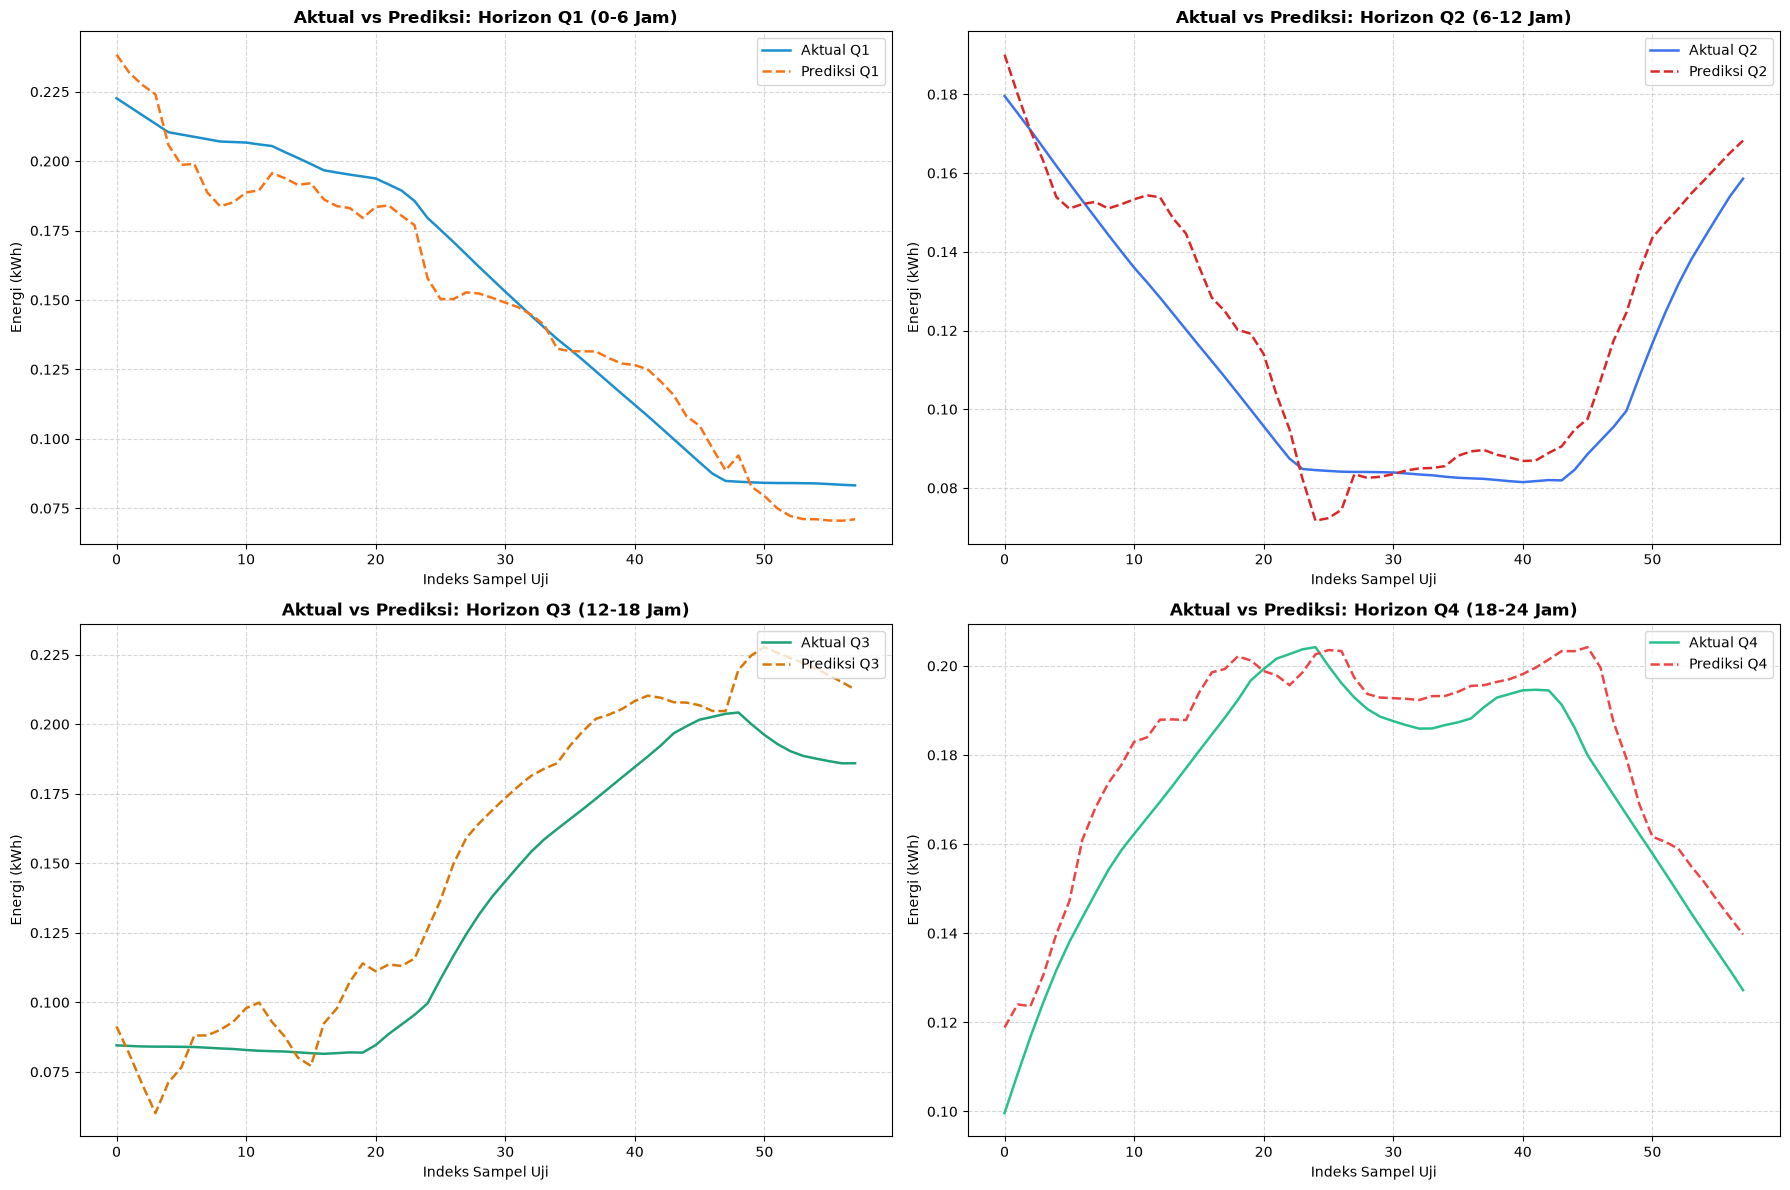

In [19]:
# ==============================================================================
# 6. EVALUASI MODEL & VISUALISASI
# ==============================================================================
print("\n[6/6] Melakukan evaluasi performa model pada data uji...")

# Prediksi akan menghasilkan nilai Z-Score
Y_pred_norm = model.predict(X_test_norm, verbose=0)

# PENTING: Denormalisasi kembali ke skala asli (kWh)
Y_pred = (Y_pred_norm * target_std) + target_mean
Y_pred = np.clip(Y_pred, 0.0, None)  # Clamping non-negatif

horizon_names = ["Q1 (0-6 jam)", "Q2 (6-12 jam)", "Q3 (12-18 jam)", "Q4 (18-24 jam)"]

print("\n" + "=" * 65)
print(f"{'HORIZON':<15} | {'MAE (kWh)':<10} | {'RMSE (kWh)':<10} | {'MAPE (%)':<10}")
print("=" * 65)

for idx, name in enumerate(horizon_names):
    y_true_h = Y_test[:, idx]
    y_pred_h = Y_pred[:, idx]

    mae = mean_absolute_error(y_true_h, y_pred_h)
    rmse = np.sqrt(mean_squared_error(y_true_h, y_pred_h))
    mask = y_true_h != 0
    mape = (np.mean(np.abs((y_true_h[mask] - y_pred_h[mask]) / y_true_h[mask])) * 100.0) if mask.sum() > 0 else 0.0

    print(f"{name:<15} | {mae:<10.4f} | {rmse:<10.4f} | {mape if mape < 1000 else 999.9:<10.2f}")
print("=" * 65)

# Membuat grid visualisasi 2x2 untuk menampung Q1, Q2, Q3, dan Q4
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Parameter warna untuk estetika
colors_actual = ["#0284c7", "#2563eb", "#059669", "#10b981"]
colors_pred = ["#f97316", "#dc2626", "#d97706", "#ef4444"]
titles = [
    "Aktual vs Prediksi: Horizon Q1 (0-6 Jam)",
    "Aktual vs Prediksi: Horizon Q2 (6-12 Jam)",
    "Aktual vs Prediksi: Horizon Q3 (12-18 Jam)",
    "Aktual vs Prediksi: Horizon Q4 (18-24 Jam)"
]
labels_act = ["Aktual Q1", "Aktual Q2", "Aktual Q3", "Aktual Q4"]
labels_prd = ["Prediksi Q1", "Prediksi Q2", "Prediksi Q3", "Prediksi Q4"]

# Looping untuk memetakan 4 grafik secara otomatis
for idx in range(4):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    ax.plot(Y_test[:, idx], label=labels_act[idx], color=colors_actual[idx], lw=1.8, alpha=0.9)
    ax.plot(Y_pred[:, idx], label=labels_prd[idx], color=colors_pred[idx], ls="--", lw=1.8)
    
    ax.set_title(titles[idx], fontsize=12, fontweight="bold")
    ax.set_xlabel("Indeks Sampel Uji")
    ax.set_ylabel("Energi (kWh)")
    ax.legend(loc="upper right")
    ax.grid(True, ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 5. Ekspor Parameter C++ Header
Mengekstrak bobot matriks layer dari model yang sudah di-fine-tune beserta statistik fitur, serta mendesak mean/std target menjadi 0 dan 1 agar model memprediksi energi langsung dalam skala kWh.

In [20]:
# ==============================================================================
# 7. EKSPOR PARAMETER BOBOT & Z-SCORE KE tinyml_model.h
# ==============================================================================
print("\n[Mengekstrak file C++ Header...]")
w1, b1 = model.get_layer("hidden_layer_1").get_weights()
w2, b2 = model.get_layer("hidden_layer_2").get_weights()
w3, b3 = model.get_layer("output_horizons").get_weights()

def format_1d(arr):
    return "  " + ", ".join([f"{v:.7f}f" for v in arr])

header_code = f"""#ifndef TINYML_MODEL_H
#define TINYML_MODEL_H

#define N_INPUT 8
#define N_HIDDEN1 24
#define N_HIDDEN2 12
#define N_OUTPUT 4
const float LEAKY_SLOPE = 0.01f;

// 1. Z-Score Fitur Masukan
const float FEATURE_MEAN[8] = {{\n{format_1d(feat_mean)}\n}};
const float FEATURE_STD[8] = {{\n{format_1d(feat_std)}\n}};

// 2. PERBAIKAN: Gunakan TARGET_MEAN dan TARGET_STD Asli untuk Denormalisasi di ESP32
const float TARGET_MEAN[4] = {{\n{format_1d(target_mean)}\n}};
const float TARGET_STD[4] = {{\n{format_1d(target_std)}\n}};

// 3. Bobot Jaringan
const float W_LAYER1[192] = {{\n{format_1d(w1.flatten())}\n}};
const float B_LAYER1[24] = {{\n{format_1d(b1)}\n}};

const float W_LAYER2[288] = {{\n{format_1d(w2.flatten())}\n}};
const float B_LAYER2[12] = {{\n{format_1d(b2)}\n}};

const float W_LAYER3[48] = {{\n{format_1d(w3.flatten())}\n}};
const float B_LAYER3[4] = {{\n{format_1d(b3)}\n}};

#endif // TINYML_MODEL_H
"""

with open("tinyml_model.h", "w") as f:
    f.write(header_code)
print("[SUKSES] Berkas 'tinyml_model.h' berhasil diperbarui!")


[Mengekstrak file C++ Header...]
[SUKSES] Berkas 'tinyml_model.h' berhasil diperbarui!
